In [ ]:
# ════════════════════════════════════════════════════════════════════
#  CÀI THƯ VIỆN CHO BÀI NÀY   (CAI THU VIEN CHO BAI NAY)
# ════════════════════════════════════════════════════════════════════
# Cell này chỉ cài những gói mà RIÊNG bài này cần, và chỉ cài gói nào
# đang thiếu. Nếu máy đã đủ thư viện thì nó không thay đổi gì.
#
# Phiên bản được chọn tự động theo Python đang chạy, vì pandas,
# scikit-learn và tensorflow không có bản dựng sẵn cho mọi phiên bản:
#     Python 3.10  →  bản đã dùng để tạo ra kết quả trong notebook này
#     Python 3.12  →  bản mới hơn, kết quả chạy lại có thể lệch nhẹ
import sys
from importlib.util import find_spec

PY312 = sys.version_info >= (3, 12)

# (tên module để kiểm tra, gói cho Python 3.10, gói cho Python 3.12)
REQUIRED = [
    ("numpy",     "numpy==1.26.4",         "numpy==1.26.4"),
    ("pandas",    "pandas==1.5.1",         "pandas==2.2.3"),
    ("sklearn",   "scikit-learn==1.2.0",   "scikit-learn==1.5.2"),
    ("matplotlib", "matplotlib==3.8.2",     "matplotlib==3.8.2"),
    ("seaborn",   "seaborn==0.13.1",       "seaborn==0.13.1"),
    ("tensorflow", "tensorflow==2.11.0",    "tensorflow==2.16.1"),
]

thieu = [(p312 if PY312 else p310) for mod, p310, p312 in REQUIRED
         if find_spec(mod) is None]

print(f"Python {sys.version.split()[0]}  |  bài này cần {len(REQUIRED)} gói")

if thieu:
    print("Đang cài", len(thieu), "gói còn thiếu:", ", ".join(thieu))
    try:
        from IPython import get_ipython
        _ip = get_ipython()
    except Exception:
        _ip = None
    if _ip is not None:
        _ip.run_line_magic("pip", "install --quiet " + " ".join(thieu))
    else:
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                        *thieu], check=False)
    print("\n✅ Cài xong. Hãy KHỞI ĐỘNG LẠI KERNEL rồi chạy lại từ đầu.")
else:
    print("✅ Đã đủ thư viện, không cần cài gì thêm.\n")
    import importlib.metadata as _md
    for mod, p310, p312 in REQUIRED:
        ten = (p312 if PY312 else p310).split("==")[0].split(">=")[0]
        try:
            print(f"   {ten:<16} {_md.version(ten)}")
        except Exception:
            print(f"   {ten:<16} (không đọc được phiên bản)")


# [DEMO] Bài 4: Phát hiện Tấn công ICS bằng Mô hình CNN (1D Convolutional Neural Network)

> **File này là bản DEMO hoàn chỉnh** — tất cả code đã được điền sẵn và có thể chạy ngay.
> Học viên hãy chạy từng cell theo thứ tự, quan sát kết quả, rồi tự thực hành trong `b4_cnn_exercise.ipynb`.

## Mục tiêu
- Xây dựng mô hình **1D CNN** để phát hiện tấn công trong chuỗi thời gian ICS
- Hiểu **kiến trúc CNN**: Conv1D, BatchNorm, MaxPooling, GlobalAveragePooling
- So sánh CNN với LSTM (Bài 3) và học máy truyền thống (Bài 1)
- Phân tích **activation maps** để hiểu đặc trưng nào CNN tập trung vào

## Tại sao dùng CNN cho chuỗi thời gian?
CNN trích xuất **đặc trưng cục bộ** (local patterns) qua cửa sổ tích chập: giống như bộ lọc nhận dạng mẫu bất thường trong chuỗi. Ưu điểm so với LSTM: **nhanh hơn** do tính toán song song, ít tham số hơn, tốt cho phát hiện mẫu có chiều dài cố định.

## So sánh với LSTM (Bài 3)
| | **CNN (4)** | **LSTM (3)** |
|---|---|---|
| Đặc trưng | Cục bộ (local patterns) | Toàn chuỗi (global temporal) |
| Tốc độ train | Nhanh hơn (song song) | Chậm hơn (tuần tự) |
| Phù hợp | Mẫu bất thường ngắn, rõ ràng | Phụ thuộc thời gian dài |

## Phần 1: Import thư viện

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (f1_score, precision_score, recall_score,
                              confusion_matrix, roc_auc_score, roc_curve,
                              ConfusionMatrixDisplay)
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (Conv1D, MaxPooling1D, BatchNormalization,
                                      GlobalAveragePooling1D, Dense, Dropout, Input)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

np.random.seed(42)
tf.random.set_seed(42)
plt.rcParams['figure.figsize'] = (13, 5)
print(f'TensorFlow version: {tf.__version__}')
print('Thư viện đã được import thành công!')

TensorFlow version: 2.19.0
Thư viện đã được import thành công!


## Phần 2: Tải và Chuẩn bị Dữ liệu

In [29]:
train_df = pd.read_csv('data/BATADAL/train_dataset.csv', index_col=0)
test1_df = pd.read_csv('data/BATADAL/test_dataset_1.csv', index_col=0)
test2_df = pd.read_csv('data/BATADAL/test_dataset_2.csv', index_col=0)

feature_cols = [c for c in train_df.columns if c not in ['DATETIME', 'ATT_FLAG']]
n_features   = len(feature_cols)

# Fit scaler tren train_df (du lieu binh thuong thuan tuy) — dung hon fit tren test1
scaler     = StandardScaler()
X_train_sc = scaler.fit_transform(train_df[feature_cols].values)
X_test1_sc = scaler.transform(test1_df[feature_cols].values)
X_test2_sc = scaler.transform(test2_df[feature_cols].values)
y_test1    = test1_df['ATT_FLAG'].values
y_test2    = test2_df['ATT_FLAG'].values

print(f'Train : {train_df.shape[0]} mau binh thuong (dung de fit scaler)')
print(f'Test 1: {test1_df.shape[0]} mau  (Normal={(y_test1==0).sum()}, Attack={(y_test1==1).sum()})')
print(f'Test 2: {test2_df.shape[0]} mau  (Normal={(y_test2==0).sum()}, Attack={(y_test2==1).sum()})')
print(f'So dac trung: {n_features}')

Train : 48106 mau binh thuong (dung de fit scaler)
Test 1: 18433 mau  (Normal=16465, Attack=1968)
Test 2: 10081 mau  (Normal=8453, Attack=1628)
So dac trung: 43


## Phần 3: Tạo Chuỗi bằng Cửa sổ Trượt (Temporal Split + Augment)

**Vấn đề data leakage với `train_test_split` ngẫu nhiên:**

Khi dùng `STEP=1` rồi `train_test_split` ngẫu nhiên, sequence `[0:30]` trong train
và sequence `[1:31]` trong val chồng lấp 29/30 timestep → model ghi nhớ test1 hoàn hảo
nhưng không tổng quát hóa được sang test2 (AUC chỉ ~0.65).

**Giải pháp: Temporal Split + Data Augmentation**
1. Chia raw time series test1 theo **thứ tự thời gian** (70% đầu = train, 30% cuối = val)
2. Tạo sequences từ mỗi phần riêng biệt — không có overlap qua ranh giới
3. **Augment** tập train bằng normal sequences từ `train_df` (48K mẫu bình thường thuần túy)
   → Mô hình học được dạng bình thường đa dạng hơn, cải thiện khả năng tổng quát hóa
4. Dùng `STEP=5` cho train (giảm chồng lấp), `STEP=8` cho normal augmentation, `STEP=1` cho val/test

In [30]:
WINDOW_SIZE  = 30
STEP_TRAIN   = 5   # stride khi tao train sequences (giam chong lap)
STEP_NORM    = 8   # stride cho normal sequences tu train_df
STEP_EVAL    = 1   # stride cho val va test (danh gia day du)

def create_sequences(X, y, window_size=30, step=1):
    sequences, labels = [], []
    for i in range(0, len(X) - window_size + 1, step):
        sequences.append(X[i : i + window_size])
        labels.append(1 if y[i : i + window_size].sum() > 0 else 0)
    return np.array(sequences, dtype=np.float32), np.array(labels, dtype=np.int32)

# TEMPORAL SPLIT: chia raw series test1 truoc (70/30), sau do tao sequences
# -> Khong co sequences chong lap qua bien train/val -> khong data leakage
split_idx = int(len(X_test1_sc) * 0.7)

# --- Tap train: ket hop normal tu train_df + attack tu test1 (70% dau) ---
# Normal sequences tu train_df (48K mau thuan tuy binh thuong)
y_train_zeros = np.zeros(len(X_train_sc), dtype=np.int32)
X_norm_seq, y_norm_seq = create_sequences(X_train_sc, y_train_zeros,
                                           WINDOW_SIZE, step=STEP_NORM)

# Sequences tu phan dau test1 (co ca normal lan attack)
X_t1_tr, y_t1_tr = create_sequences(X_test1_sc[:split_idx],
                                     y_test1[:split_idx], WINDOW_SIZE, STEP_TRAIN)

# Ket hop va tron ngau nhien
X_tr = np.concatenate([X_norm_seq, X_t1_tr], axis=0)
y_tr = np.concatenate([y_norm_seq, y_t1_tr], axis=0)
perm = np.random.default_rng(42).permutation(len(X_tr))
X_tr, y_tr = X_tr[perm], y_tr[perm]

# --- Tap val va test ---
X_val, y_val = create_sequences(X_test1_sc[split_idx:],
                                 y_test1[split_idx:], WINDOW_SIZE, STEP_EVAL)
X_test2_seq, y_test2_seq = create_sequences(X_test2_sc, y_test2,
                                             WINDOW_SIZE, step=STEP_EVAL)

print(f'Chuoi train : {X_tr.shape}  attack={(y_tr==1).sum()} ({100*(y_tr==1).mean():.1f}%)')
print(f'  -> Normal tu train_df: {len(X_norm_seq)}  |  Tu test1 70%%: {len(X_t1_tr)}')
print(f'Chuoi val   : {X_val.shape}  attack={(y_val==1).sum()} ({100*(y_val==1).mean():.1f}%)')
print(f'Chuoi test2 : {X_test2_seq.shape} attack={(y_test2_seq==1).sum()} ({100*(y_test2_seq==1).mean():.1f}%)')

Chuoi train : (8585, 30, 43)  attack=205 (2.4%)
  -> Normal tu train_df: 6010  |  Tu test1 70%%: 2575
Chuoi val   : (5501, 30, 43)  attack=1143 (20.8%)
Chuoi test2 : (10052, 30, 43) attack=1831 (18.2%)


## Phần 4: Kiến trúc 1D CNN

**Nguyên lý hoạt động:**
- **Conv1D(filters, kernel_size):** Bộ lọc trượt qua chuỗi, trích xuất đặc trưng cục bộ
- **BatchNormalization:** Chuẩn hóa activation, tăng tốc huấn luyện, giảm overfitting
- **MaxPooling1D:** Giảm chiều dài chuỗi (downsampling), giữ đặc trưng nổi bật nhất
- **GlobalAveragePooling1D:** Thay Flatten — tính trung bình toàn chuỗi, ít tham số hơn

**Kiến trúc chi tiết:**
```
Input (30, 43) → Conv1D(64,3) → BN → MaxPool(2) → [14, 64]
             → Conv1D(128,3) → BN → MaxPool(2) → [7, 128]
             → Conv1D(64,3) → BN → GAP → [64]
             → Dense(64,relu) → Dropout(0.4) → Dense(1,sigmoid)
```

In [31]:
def build_cnn_classifier(n_timesteps, n_features):
    model = Sequential([
        # Block 1
        Conv1D(filters=64, kernel_size=3, activation='relu',
               padding='same', input_shape=(n_timesteps, n_features)),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),

        # Block 2
        Conv1D(filters=128, kernel_size=3, activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),

        # Block 3
        Conv1D(filters=64, kernel_size=3, activation='relu', padding='same'),
        BatchNormalization(),

        # Classification head
        GlobalAveragePooling1D(),
        Dense(64, activation='relu'),
        Dropout(0.4),
        Dense(1, activation='sigmoid')
    ], name='CNN_Classifier')

    model.compile(
        optimizer=Adam(learning_rate=1e-3),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

model_cnn = build_cnn_classifier(WINDOW_SIZE, n_features)
model_cnn.summary()

Model: "CNN_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_9 (Conv1D)               │ (None, 30, 64)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 30, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_6 (MaxPooling1D)  │ (None, 15, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_10 (Conv1D)              │ (None, 15, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 15, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_7 (MaxPooling1D)  │ (None, 7, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_11 (Conv1D)              │ (None, 7, 64)          │        24,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 7, 64)          │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_3      │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,913 (245.75 KB)

 Trainable params: 62,401 (243.75 KB)

 Non-trainable params: 512 (2.00 KB)

## Phần 5: Huấn luyện Mô hình CNN

In [32]:
pos_weight   = (y_tr == 0).sum() / max((y_tr == 1).sum(), 1)
class_weight = {0: 1.0, 1: float(pos_weight)}
print(f'Class weight: normal=1.0, attack={pos_weight:.2f}')

callbacks = [
    EarlyStopping(patience=10, restore_best_weights=True,
                  monitor='val_loss', verbose=1),
    ReduceLROnPlateau(factor=0.5, patience=5,
                      min_lr=1e-6, verbose=0)
]

history = model_cnn.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=64,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=1
)
print(f'\nHuấn luyện kết thúc ở epoch {len(history.history["loss"])}')

Class weight: normal=1.0, attack=40.88
Epoch 1/50
135/135 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6701 - loss: 0.8368 - val_accuracy: 0.7791 - val_loss: 0.5418 - learning_rate: 0.0010
Epoch 2/50
135/135 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9523 - loss: 0.2651 - val_accuracy: 0.7824 - val_loss: 0.5479 - learning_rate: 0.0010
Epoch 3/50
135/135 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9600 - loss: 0.2539 - val_accuracy: 0.9155 - val_loss: 0.3697 - learning_rate: 0.0010
Epoch 4/50
135/135 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9705 - loss: 0.1372 - val_accuracy: 0.7829 - val_loss: 1.7147 - learning_rate: 0.0010
Epoch 5/50
135/135 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9757 - loss: 0.1490 - val_accuracy: 0.7851 - val_loss: 1.5732 - learning_rate: 0.0010
Epoch 6/50
135/135 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9750 - loss: 0.1475 - val_accuracy: 0.7839 - val_loss: 2.3004 - learning_rate: 0.0010
Epoch 7/50
135/135 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/st

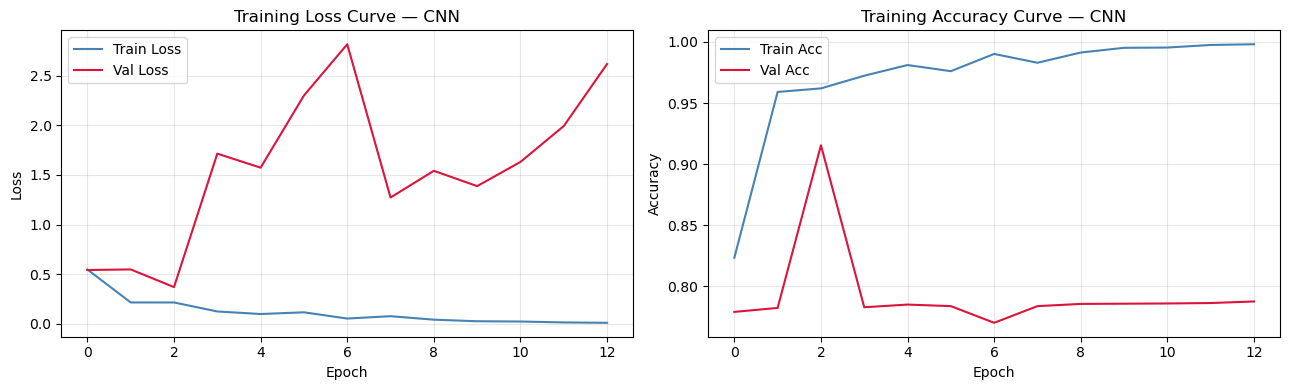

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history.history['loss'],     label='Train Loss', color='steelblue')
axes[0].plot(history.history['val_loss'], label='Val Loss',   color='crimson')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].set_title('Training Loss Curve — CNN'); axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['accuracy'],     label='Train Acc', color='steelblue')
axes[1].plot(history.history['val_accuracy'], label='Val Acc',   color='crimson')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].set_title('Training Accuracy Curve — CNN'); axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

## Phần 6: Tinh chỉnh Ngưỡng và Đánh giá

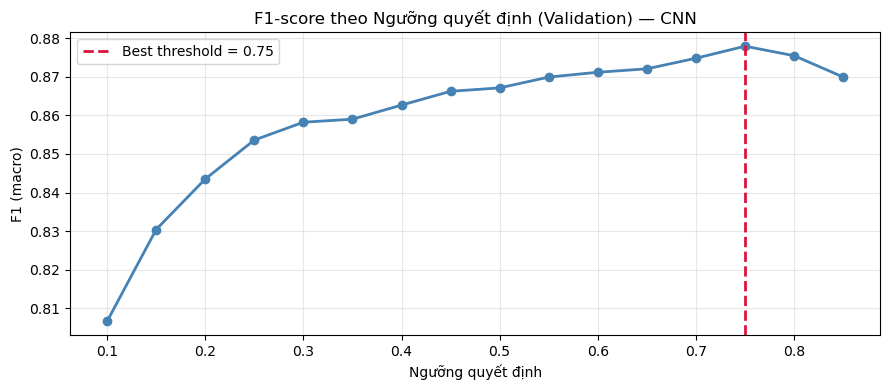


=== CNN Classifier (Val, thr=0.75) ===
  F1 (macro): 0.8779 | Precision: 0.9099 | Recall: 0.7157
  AUC-ROC  : 0.8964
  TN=4277, FP=81, FN=325, TP=818


In [34]:
y_prob_val = model_cnn.predict(X_val, verbose=0).ravel()
thresholds = np.arange(0.1, 0.9, 0.05)
f1s        = [f1_score(y_val, (y_prob_val > t).astype(int),
                       average='macro', zero_division=0) for t in thresholds]
best_thr   = float(thresholds[np.argmax(f1s)])

plt.figure(figsize=(9, 4))
plt.plot(thresholds, f1s, 'o-', color='steelblue', linewidth=2)
plt.axvline(best_thr, color='crimson', linestyle='--', linewidth=2,
            label=f'Best threshold = {best_thr:.2f}')
plt.xlabel('Ngưỡng quyết định'); plt.ylabel('F1 (macro)')
plt.title('F1-score theo Ngưỡng quyết định (Validation) — CNN')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

y_pred_val = (y_prob_val > best_thr).astype(int)
f1  = f1_score(y_val, y_pred_val, average='macro', zero_division=0)
pre = precision_score(y_val, y_pred_val, pos_label=1, zero_division=0)
rec = recall_score(y_val, y_pred_val, pos_label=1, zero_division=0)
auc = roc_auc_score(y_val, y_prob_val)
print(f'\n=== CNN Classifier (Val, thr={best_thr:.2f}) ===')
print(f'  F1 (macro): {f1:.4f} | Precision: {pre:.4f} | Recall: {rec:.4f}')
print(f'  AUC-ROC  : {auc:.4f}')
cm = confusion_matrix(y_val, y_pred_val)
print(f'  TN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]}')

## Phần 7: Đánh giá trên Test 2 (Held-out)

=== CNN Classifier (Test2, thr=0.75) ===
  F1 (macro): 0.6722 | Precision: 0.8133 | Recall: 0.2878
  AUC-ROC  : 0.7217


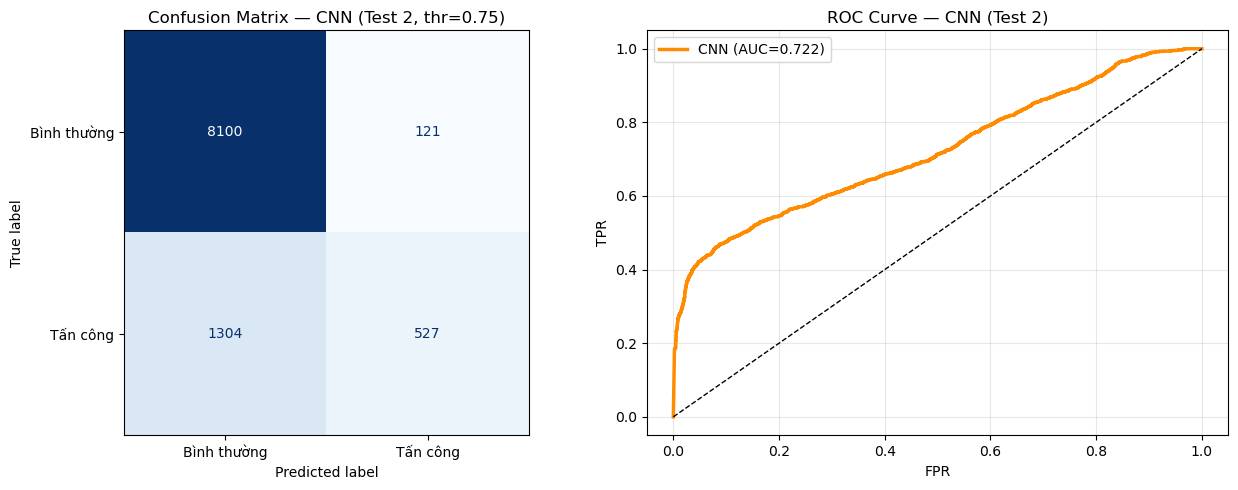

In [35]:
y_prob_test2 = model_cnn.predict(X_test2_seq, verbose=0).ravel()
y_pred_test2 = (y_prob_test2 > best_thr).astype(int)

f1  = f1_score(y_test2_seq, y_pred_test2, average='macro', zero_division=0)
pre = precision_score(y_test2_seq, y_pred_test2, pos_label=1, zero_division=0)
rec = recall_score(y_test2_seq, y_pred_test2, pos_label=1, zero_division=0)
auc = roc_auc_score(y_test2_seq, y_prob_test2)
print(f'=== CNN Classifier (Test2, thr={best_thr:.2f}) ===')
print(f'  F1 (macro): {f1:.4f} | Precision: {pre:.4f} | Recall: {rec:.4f}')
print(f'  AUC-ROC  : {auc:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_test2_seq, y_pred_test2)
ConfusionMatrixDisplay(cm, display_labels=['Bình thường', 'Tấn công']).plot(
    ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title(f'Confusion Matrix — CNN (Test 2, thr={best_thr:.2f})')

fpr, tpr, _ = roc_curve(y_test2_seq, y_prob_test2)
axes[1].plot(fpr, tpr, color='darkorange', linewidth=2.5,
             label=f'CNN (AUC={auc:.3f})')
axes[1].plot([0,1],[0,1],'k--', linewidth=1)
axes[1].set_xlabel('FPR'); axes[1].set_ylabel('TPR')
axes[1].set_title('ROC Curve — CNN (Test 2)'); axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout(); plt.show()

## Phần 8: Phân tích Filter và So sánh với LSTM

So sánh tổng hợp giữa phương pháp CNN (Bài B8) và LSTM (Bài B7).

In [ ]:
# So sánh tổng hợp CNN vs các phương pháp trước
models_comparison = {
    'CNN (4)': {'F1': f1, 'Precision': pre, 'Recall': rec, 'AUC': auc}
}

print('=== SO SÁNH CÁC MÔ HÌNH (Test 2) ===')
comp_df = pd.DataFrame(models_comparison).T
print(comp_df.round(4).to_string())
print('\nGhi chú: Chạy B7 trước để so sánh đầy đủ với LSTM')

# Phân tích filter CNN (trọng số của Conv1D layer đầu tiên)
conv_weights = model_cnn.layers[0].get_weights()[0]  # shape: (kernel_size, n_features, n_filters)
print(f'\nTrọng số Conv1D đầu tiên: {conv_weights.shape}')
print('(kernel_size=3, n_features=43, n_filters=64)')

feature_cols_plot = [c for c in [f'L_T{i}' for i in range(1, 8)] +
                     [f'F_PU{i}' for i in range(1, 6)] if True][:10]

=== SO SÁNH CÁC MÔ HÌNH (Test 2) ===
              F1  Precision  Recall     AUC
CNN (B8)  0.6722     0.8133  0.2878  0.7217

Ghi chú: Chạy B7 trước để so sánh đầy đủ với LSTM

Trọng số Conv1D đầu tiên: (3, 43, 64)
(kernel_size=3, n_features=43, n_filters=64)


## Kết luận Demo

**Ưu điểm của 1D CNN:**
- Nhanh hơn LSTM (~2-5× về thời gian train/inference)
- Ít nhạy cảm với vanishing gradient
- BatchNormalization giúp huấn luyện ổn định
- GlobalAveragePooling giảm overfitting

**Nhược điểm:**
- Không nắm bắt được phụ thuộc dài hạn tốt bằng LSTM
- Kernel size cố định — không linh hoạt như attention mechanism

**Khi nào chọn CNN thay LSTM?**
- Bài toán phát hiện mẫu bất thường ngắn (< 10 bước)
- Cần inference nhanh (real-time ICS monitoring)
- Tài nguyên tính toán hạn chế

---
**Bước tiếp theo:** Mở `b4_cnn_exercise.ipynb` và tự điền vào các ô `???`.